# Vectores, pesos y el problema de leer en cadena

**Materiales desarrollados por Matías Barreto, 2026**

**Tecnicatura Superior en Ciencias de Datos e IA, IFTS N.º 24**
* **Nomenclatura oficial:** Procesamiento de Lenguaje Natural
* **Nombre de trabajo:** Laboratorio de PLN: Analítica, Textos y Cultura

---

| | |
|---|---|
| **Problema** | Un modelo no recibe palabras sino números, y para relacionar dos palabras lejanas, leer de a una obliga a pasar por todas las del medio. |
| **Producto** | El vector real de un token con su posición, una neurona real calculada a mano y comprobada, y una medición de cuánto conecta la atención dos tokens lejanos. |
| **Recursos** | GPT-2 en español (`DeepESP/gpt2-spanish`, unos 250 MB, descargado antes de la clase según `ANTES_DE_LA_CLASE.md`). Corre en CPU en pocos segundos. |

En la unidad 010 usamos modelos preentrenados como herramientas. Ahora abrimos uno por dentro, con sus números reales: qué recibe en lugar de una palabra, cómo la transforma una neurona y por qué hizo falta un mecanismo nuevo para conectar palabras lejanas.

**¿Qué recibe un modelo en lugar de una palabra, qué hace una neurona con eso, y qué cambia cuando puede conectar directamente dos palabras lejanas?**

> **Cómo se trabaja.** Recorrés el primer verso del *Martín Fierro* tal como lo ve GPT-2. Cada cuenta que hacemos a mano se compara con la que hace el modelo. Al final de las secciones 2 y 3 hay un **microlaboratorio**: una tabla te dice qué líneas completar y con qué, y la celda siguiente comprueba si quedó bien.

In [1]:
import numpy as np
import torch
import transformers

import utils

# Muestra los numeros con dos decimales y sin notacion cientifica.
np.set_printoptions(precision=2, suppress=True)

version_de_numpy = np.__version__
version_de_torch = torch.__version__
version_de_transformers = transformers.__version__
print(f"numpy {version_de_numpy}, torch {version_de_torch}, "
      f"transformers {version_de_transformers}")

numpy 2.5.4, torch 2.14.1+cpu, transformers 4.57.6


## 1. Un token llega como un vector

| | |
|---|---|
| **Modelo** | `DeepESP/gpt2-spanish`: GPT-2 pequeño, de Alejandro Oñate Latorre y Jorge Ortiz Fuentes (comunidad DeepESP), licencia MIT. Es el mismo de toda la unidad y de la 012. |
| **Datos** | Según su ficha: 11,5 GB de textos en español (3,5 GB de Wikipedia y 8 GB de libros), **sin filtrar**. No se publicó la lista de libros. |
| **Qué hace** | Dado un texto, puntúa cuál podría ser el próximo token. |

In [2]:
tokenizador, modelo = utils.cargar_gpt2()

El verso es el comienzo de *El gaucho Martín Fierro* (José Hernández, 1872, dominio público). El **tokenizador** lo corta en piezas, los **tokens**, y cambia cada una por su número en el vocabulario.

**Python nuevo:** `return_tensors="pt"` pide el resultado como *tensor* de PyTorch, el formato que recibe el modelo. El `[0]` aparece porque el modelo puede recibir varios textos a la vez: le damos uno solo, el primero.

In [3]:
verso = "Aquí me pongo a cantar al compás de la vigüela"
codificado = tokenizador(verso, return_tensors="pt")
ids_del_verso = codificado["input_ids"]

tokens = []
rotulos = []
numeros_del_verso = []
for numero in ids_del_verso[0]:
    token = tokenizador.decode(numero)
    tokens.append(token)
    rotulos.append(token.strip())
    numeros_del_verso.append(int(numero))

cantidad_de_tokens = len(tokens)
print(f"{cantidad_de_tokens} tokens: {tokens}")

12 tokens: ['Aquí', ' me', ' pongo', ' a', ' cantar', ' al', ' compás', ' de', ' la', ' vig', 'ü', 'ela']


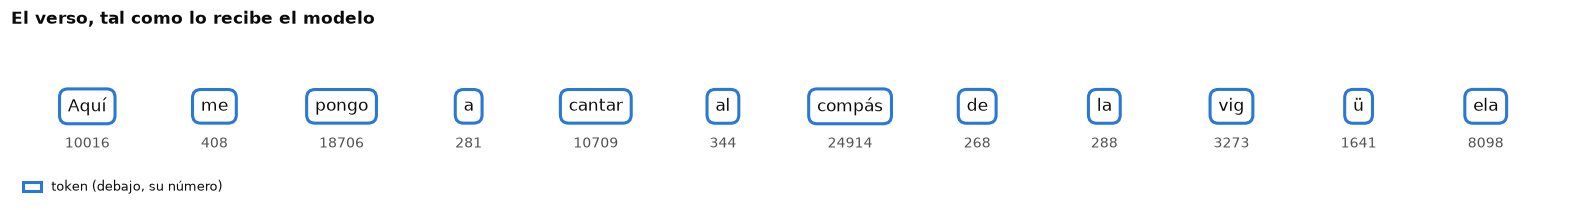

In [4]:
notas = []
for numero in numeros_del_verso:
    notas.append(str(numero))

utils.dibujar_fichas(
    piezas=rotulos,
    clases=["token"] * cantidad_de_tokens,
    estilos={"token": (utils.AZUL, "token (debajo, su n\u00famero)")},
    titulo="El verso, tal como lo recibe el modelo",
    notas=notas,
)

> **Para mirar.** Casi todas las palabras son un token entero; *vigüela* se parte en tres (`vig`, `ü`, `ela`) porque no está entera en el vocabulario. El espacio va pegado al comienzo del token (`" me"`): los rótulos lo esconden.

**Del número al vector.** El modelo guarda una **tabla de embeddings**: una fila por token del vocabulario, 768 números por fila. Recibir «cantar» es buscar su fila. Para que los 768 números entren en pantalla, los dibujamos de a 64 por renglón (`reshape` cambia la forma, no los números).

Tabla de embeddings: (50257, 768)


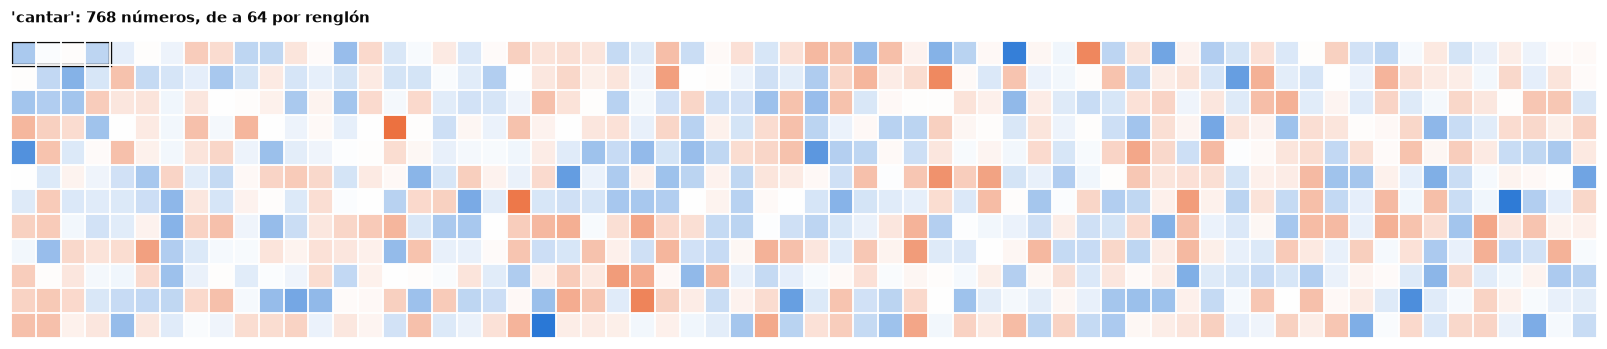

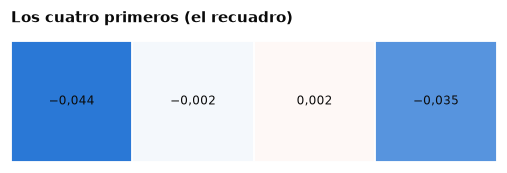

In [5]:
tabla_de_embeddings = modelo.transformer.wte.weight.detach().numpy()
print(f"Tabla de embeddings: {tabla_de_embeddings.shape}")

posicion_de_cantar = 4
id_de_cantar = numeros_del_verso[posicion_de_cantar]
vector_de_cantar = tabla_de_embeddings[id_de_cantar]

utils.dibujar_paneles(paneles=[{
    "matriz": vector_de_cantar.reshape(12, 64), "tipo": "vector",
    "marco": (0, 0, 1, 4),
    "titulo": "'cantar': 768 n\u00fameros, de a 64 por rengl\u00f3n",
}])
utils.dibujar_paneles(paneles=[{
    "matriz": vector_de_cantar[0:4], "tipo": "vector", "numeros": True,
    "decimales": 3, "titulo": "Los cuatro primeros (el recuadro)",
}])

> **Para mirar.** Naranja es positivo y azul, negativo. Los números son chicos (−0,044, −0,002…) y ninguno significa algo por sí solo: nadie los escribió; salieron del entrenamiento.

**¿Qué guardan, entonces?** Una forma de averiguarlo es buscar los tokens cuyo vector se parece más al de «cantar». Usamos el **coseno**, como en la unidad 009: 1 si los vectores apuntan para el mismo lado, 0 si no tienen nada en común.

**Python nuevo:** `np.linalg.norm` calcula el largo de cada vector (`axis=1`: uno por fila). `np.argsort` ordena posiciones de menor a mayor; con el signo menos, de mayor a menor.

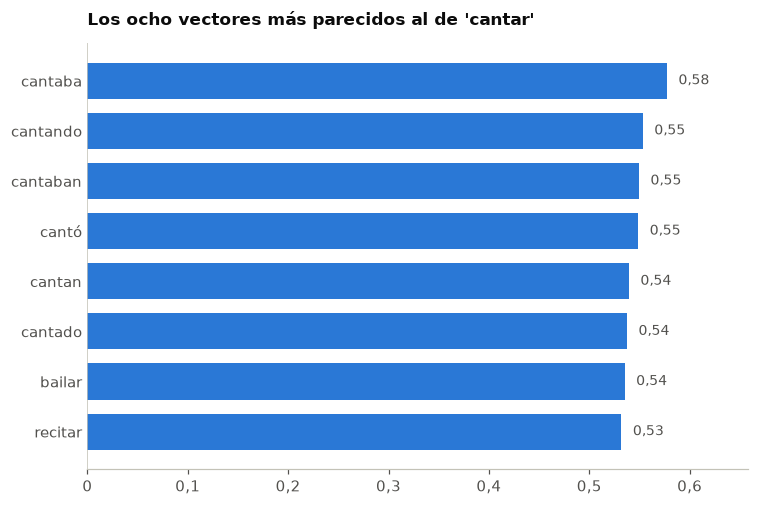

In [6]:
largos = np.linalg.norm(tabla_de_embeddings, axis=1)
productos = tabla_de_embeddings @ vector_de_cantar
cosenos = productos / (largos * largos[id_de_cantar])

orden = np.argsort(-cosenos)
nombres_de_vecinos = []
cosenos_de_vecinos = []
# El primero del orden es 'cantar' mismo: empezamos en el segundo.
for numero in orden[1:9]:
    nombres_de_vecinos.append(tokenizador.decode(int(numero)).strip())
    cosenos_de_vecinos.append(cosenos[numero])

utils.dibujar_barras(
    nombres=nombres_de_vecinos,
    valores=cosenos_de_vecinos,
    titulo="Los ocho vectores m\u00e1s parecidos al de 'cantar'",
    color=utils.AZUL,
)

Lo mismo, encapsulado en una función, para «compás».

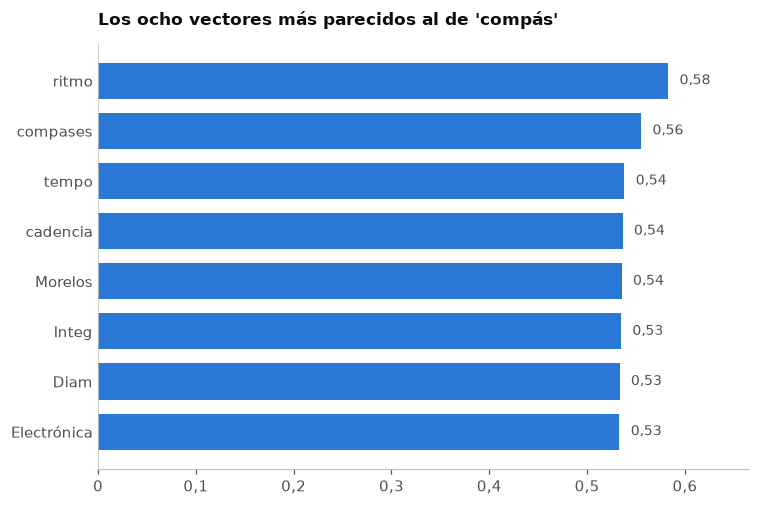

In [7]:
def vecinos_de(id_del_token: int, cantidad: int) -> dict:
    """Busca los tokens con el vector mas parecido, por coseno.

    Args:
        id_del_token: Numero del token en el vocabulario.
        cantidad: Cuantos vecinos devolver.

    Returns:
        Diccionario con los nombres y los cosenos de los vecinos.
    """
    vector = tabla_de_embeddings[id_del_token]
    cosenos = tabla_de_embeddings @ vector / (largos * largos[id_del_token])
    orden = np.argsort(-cosenos)
    nombres = []
    valores = []
    for numero in orden[1:cantidad + 1]:
        nombres.append(tokenizador.decode(int(numero)).strip())
        valores.append(cosenos[numero])
    return {"nombres": nombres, "cosenos": valores}


vecinos_de_compas = vecinos_de(numeros_del_verso[6], cantidad=8)
utils.dibujar_barras(
    nombres=vecinos_de_compas["nombres"],
    valores=vecinos_de_compas["cosenos"],
    titulo="Los ocho vectores m\u00e1s parecidos al de 'comp\u00e1s'",
    color=utils.AZUL,
)

> **Para mirar.**
>
> - Los vecinos de «cantar» son otras formas del verbo (*cantaba*, *cantando*, *cantó*) y verbos parecidos (*bailar*, *recitar*). La tabla aprendió algo del uso de las palabras en sus datos.
> - Los de «compás» empiezan bien (*ritmo*, *compases*, *tempo*, *cadencia*) y siguen con *Morelos* o *Electrónica*. **Que dos vectores se parezcan no garantiza que las palabras se parezcan.**

## 2. La posición también es un vector

El modelo recibe los 12 vectores **juntos**, no de a uno. Para saber en qué orden vienen, a cada token le suma el vector de su **posición**, sacado de otra tabla: una fila por posición, hasta 1024. «cantar» está en la posición 4.

Tabla de posiciones: (1024, 768)


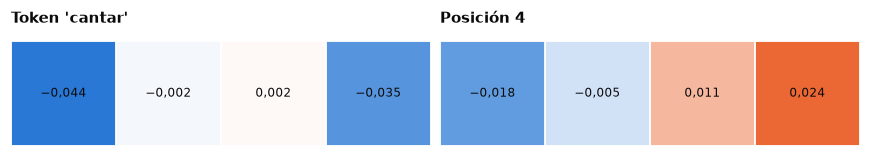

In [8]:
tabla_de_posiciones = modelo.transformer.wpe.weight.detach().numpy()
print(f"Tabla de posiciones: {tabla_de_posiciones.shape}")

vector_de_la_posicion_4 = tabla_de_posiciones[posicion_de_cantar]
utils.dibujar_paneles(paneles=[
    {"matriz": vector_de_cantar[0:4], "tipo": "vector", "numeros": True,
     "decimales": 3, "titulo": "Token 'cantar'"},
    {"matriz": vector_de_la_posicion_4[0:4], "tipo": "vector",
     "numeros": True, "decimales": 3, "titulo": "Posici\u00f3n 4"},
])

La cuenta, con las cuatro primeras coordenadas: se suman lugar por lugar.

* −0,044 + (−0,018) = −0,062
* −0,002 + (−0,005) = −0,007
* 0,002 + 0,011 = 0,013
* −0,035 + 0,024 = −0,011

El código hace la suma con los 768 números y la compara con la entrada que usa el modelo, que lo devuelve si se lo pedimos (`output_hidden_states=True`).

In [9]:
entrada_de_cantar = vector_de_cantar + vector_de_la_posicion_4
for posicion in range(4):
    print(f"Coordenada {posicion + 1}: {entrada_de_cantar[posicion]:.3f}")

with torch.no_grad():
    salida_del_modelo = modelo(ids_del_verso, output_hidden_states=True)

estados_del_modelo = salida_del_modelo.hidden_states
primer_estado = estados_del_modelo[0]
entradas_del_modelo = primer_estado[0].numpy()

diferencia = np.abs(entrada_de_cantar - entradas_del_modelo[4]).max()
print(f"Mayor diferencia con la entrada del modelo: {diferencia:.1e}")

Coordenada 1: -0.062
Coordenada 2: -0.007
Coordenada 3: 0.013
Coordenada 4: -0.011
Mayor diferencia con la entrada del modelo: 0.0e+00


> **Para mirar.** La diferencia es cero: lo que entra al modelo es exactamente token más posición. La misma palabra en otra posición entra como otro vector.

¿Cómo son esas posiciones entre sí? Comparamos, con el coseno, las 12 primeras de a pares.

**Python nuevo:** `np.outer` arma la tabla de todos los productos entre dos listas: acá, el largo de cada vector por el de cada otro.

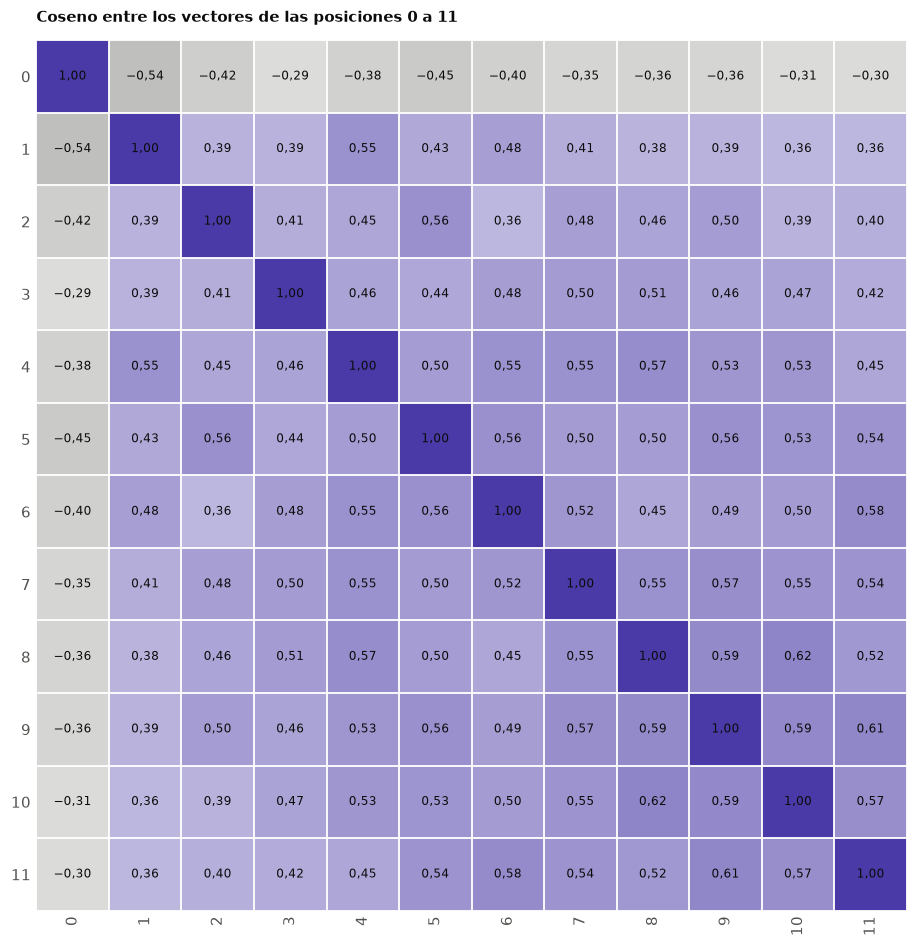

In [10]:
posiciones_del_verso = tabla_de_posiciones[0:cantidad_de_tokens]
largos_de_posiciones = np.linalg.norm(posiciones_del_verso, axis=1)
productos_entre_posiciones = posiciones_del_verso @ posiciones_del_verso.T
divisores = np.outer(largos_de_posiciones, largos_de_posiciones)
parecido_entre_posiciones = productos_entre_posiciones / divisores

nombres_de_posiciones = []
for posicion in range(cantidad_de_tokens):
    nombres_de_posiciones.append(str(posicion))

utils.dibujar_paneles(paneles=[{
    "matriz": parecido_entre_posiciones, "tipo": "puntaje", "numeros": True,
    "filas": nombres_de_posiciones, "columnas": nombres_de_posiciones,
    "titulo": "Coseno entre los vectores de las posiciones 0 a 11",
}])

> **Para mirar.** Violeta es parecido y gris, opuesto. Dentro del verso, las posiciones 1 a 11 se parecen entre sí (de 0,36 a 0,62) sin un orden claro por cercanía, y la posición 0 es opuesta a todas (con la 1: −0,54). Doce posiciones son pocas para ver si las cercanas se parecen más.

Para mirar más lejos, medimos el parecido promedio entre posiciones separadas por una distancia, recorriendo las 1024 (sin la 0, que es distinta). `(a * b).sum(axis=1)` es el producto punto fila por fila.

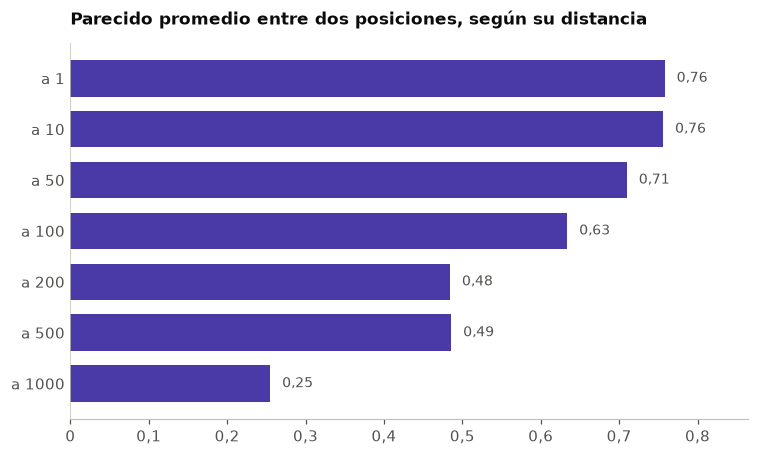

In [11]:
distancias = [1, 10, 50, 100, 200, 500, 1000]
nombres_de_distancias = []
parecidos_promedio = []
for distancia in distancias:
    primeras = tabla_de_posiciones[1:1024 - distancia]
    segundas = tabla_de_posiciones[1 + distancia:1024]
    productos = (primeras * segundas).sum(axis=1)
    largos_1 = np.linalg.norm(primeras, axis=1)
    largos_2 = np.linalg.norm(segundas, axis=1)
    cosenos_a_esa_distancia = productos / (largos_1 * largos_2)
    nombres_de_distancias.append(f"a {distancia}")
    parecidos_promedio.append(cosenos_a_esa_distancia.mean())

utils.dibujar_barras(
    nombres=nombres_de_distancias,
    valores=parecidos_promedio,
    titulo="Parecido promedio entre dos posiciones, seg\u00fan su distancia",
    color=utils.VIOLETA,
)

> **Para mirar.** Hasta 10 posiciones de distancia, el parecido casi no cambia (0,76); a 200 baja a 0,48, a 500 se mantiene (0,49) y a 1000 llega a 0,25. Las posiciones cercanas se parecen más que las lejanas, pero a escala de cientos de tokens, no de una palabra a la siguiente. Nadie diseñó esa forma: el modelo la aprendió.

### Microlaboratorio 1 — La entrada de «compás»

**Tarea.** Armar el vector con el que «compás» entra al modelo.
**Producto.** `entrada_de_compas`, comprobada contra la entrada del modelo.
**Antes de empezar.** Secciones 1 y 2.

Completá las líneas marcadas `COMPLETAR`:

| Línea | Qué tiene que quedar | Con qué |
|---|---|---|
| (1) `vector_del_token` | la fila de «compás» en la tabla de embeddings | `tabla_de_embeddings` en la fila `numeros_del_verso[posicion_de_compas]` |
| (2) `vector_de_su_posicion` | la fila de su posición | `tabla_de_posiciones` en la fila `posicion_de_compas` |
| (3) `entrada_de_compas` | la suma de los dos | `vector_del_token + vector_de_su_posicion` |

**Comprobación.** La fila 6 de `entradas_del_modelo`.

> **Ayuda 1.** Es la cuenta de «cantar», con otra posición.
> **Ayuda 2.** «compás» es el séptimo token: su posición es la 6, porque se cuenta desde 0.

In [12]:
posicion_de_compas = 6

vector_del_token = np.zeros(768)  # COMPLETAR (1)
vector_de_su_posicion = np.zeros(768)  # COMPLETAR (2)
entrada_de_compas = np.zeros(768)  # COMPLETAR (3)

print(f"Tu primera coordenada: {entrada_de_compas[0]:.3f}")

Tu primera coordenada: 0.000


In [13]:
utils.comprobar(
    np.allclose(entrada_de_compas, entradas_del_modelo[posicion_de_compas]),
    "revisa (1) a (3): la entrada no coincide con la del modelo.",
)

Todavia no. revisa (1) a (3): la entrada no coincide con la del modelo.


## 3. Una neurona real

Dentro de cada bloque, después de la atención, hay una **red** con 3072 neuronas que transforma cada token por separado. Una neurona hace una cuenta simple: multiplica cada número que entra por un peso, suma todo y agrega un **sesgo**.

Lo que entra a esa red es el vector de cada token después de la atención (cuaderno 02) y de una normalización (cuaderno 03). Acá lo tomamos tal como lo calcula el modelo. `attn` devuelve varias cosas; la primera, `[0]`, es su resultado.

In [14]:
primer_bloque = modelo.transformer.h[0]

with torch.no_grad():
    normalizada = primer_bloque.ln_1(primer_estado)
    aporte_de_la_atencion = primer_bloque.attn(normalizada)[0]
    entrada_de_la_red_tensor = primer_bloque.ln_2(
        primer_estado + aporte_de_la_atencion
    )

entrada_de_la_red = entrada_de_la_red_tensor[0].numpy()
print(f"Lo que entra a la red: {entrada_de_la_red.shape}")

Lo que entra a la red: (12, 768)


Los pesos de las 3072 neuronas están en una matriz de 768 × 3072: una columna por neurona. Elegimos la **neurona 180**, la que más se distingue con «cantar» en este verso.

Pesos de la red: (768, 3072)


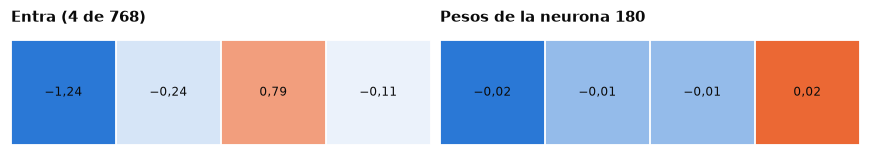

In [15]:
pesos_de_la_red = primer_bloque.mlp.c_fc.weight.detach().numpy()
sesgos_de_la_red = primer_bloque.mlp.c_fc.bias.detach().numpy()
print(f"Pesos de la red: {pesos_de_la_red.shape}")

NEURONA = 180
pesos_de_la_neurona = pesos_de_la_red[:, NEURONA]
sesgo_de_la_neurona = sesgos_de_la_red[NEURONA]
cantar_en_la_red = entrada_de_la_red[posicion_de_cantar]

recorte_de_la_entrada = np.round(cantar_en_la_red[0:4], decimals=2)
recorte_de_los_pesos = np.round(pesos_de_la_neurona[0:4], decimals=2)
utils.dibujar_paneles(paneles=[
    {"matriz": recorte_de_la_entrada, "tipo": "vector", "numeros": True,
     "titulo": "Entra (4 de 768)"},
    {"matriz": recorte_de_los_pesos, "tipo": "vector", "numeros": True,
     "titulo": "Pesos de la neurona 180"},
])

La cuenta con el recorte, escrita completa:

* −1,24 × (−0,02) = 0,0248
* −0,24 × (−0,01) = 0,0024
* 0,79 × (−0,01) = −0,0079
* −0,11 × 0,02 = −0,0022

Suma: 0,0248 + 0,0024 − 0,0079 − 0,0022 = **0,0171**. Falta repetir lo mismo con las otras 764 coordenadas y sumar el sesgo (−0,05).

**En una frase:** *cada número que entra, multiplicado por su peso; todo sumado, más el sesgo.* Con $x$ para lo que entra, $w$ para los pesos y $b$ para el sesgo:

$$x_1 w_1 + x_2 w_2 + \dots + x_{768} w_{768} + b$$

In [16]:
suma_del_recorte = 0.0
for posicion in range(4):
    aporte = recorte_de_la_entrada[posicion] * recorte_de_los_pesos[posicion]
    suma_del_recorte = suma_del_recorte + aporte

suma_completa = 0.0
for posicion in range(768):
    aporte = cantar_en_la_red[posicion] * pesos_de_la_neurona[posicion]
    suma_completa = suma_completa + aporte
salida_de_la_neurona = suma_completa + sesgo_de_la_neurona

with torch.no_grad():
    salidas_de_la_red = primer_bloque.mlp.c_fc(entrada_de_la_red_tensor)
salidas_del_verso = salidas_de_la_red[0].numpy()
del_modelo = salidas_del_verso[posicion_de_cantar, NEURONA]

print(f"Con 4 coordenadas:        {suma_del_recorte:.4f}")
print(f"Con las 768, mas sesgo:   {salida_de_la_neurona:.4f}")
print(f"La del modelo:            {del_modelo:.4f}")

Con 4 coordenadas:        0.0171
Con las 768, mas sesgo:   3.1197
La del modelo:            3.1197


> **Para mirar.** Las cuatro primeras coordenadas aportan 0,017 de un total de 3,12: la salida se arma con cientos de aportes chicos (el mayor de todos es de 0,16). Ningún número decide solo. Y nuestra cuenta da lo mismo que la del modelo.

**La misma neurona, en todos los tokens del verso.** Con `@` sale la cuenta de todas las filas a la vez.

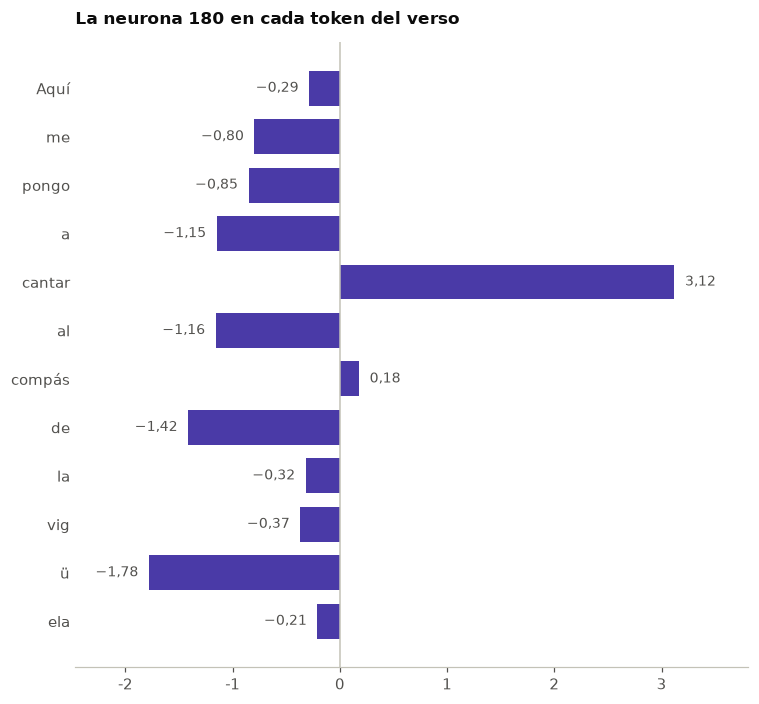

In [17]:
salidas_en_el_verso = entrada_de_la_red @ pesos_de_la_neurona
salidas_en_el_verso = salidas_en_el_verso + sesgo_de_la_neurona

utils.dibujar_barras(
    nombres=rotulos,
    valores=salidas_en_el_verso,
    titulo="La neurona 180 en cada token del verso",
    color=utils.VIOLETA,
)

> **Para mirar.** Con «cantar» da 3,12; con todos los demás tokens, 0,18 o menos. Es tentador llamarla «la neurona de cantar». Antes de ponerle nombre, una prueba: cambiamos el verbo del verso.

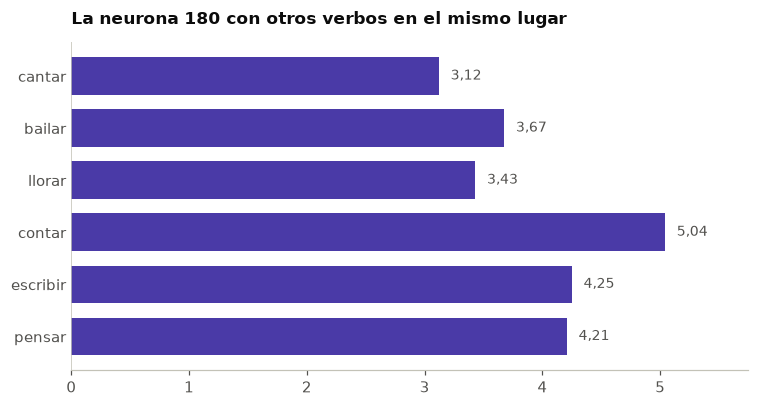

In [18]:
def neurona_con_otro_verbo(verbo: str) -> float:
    """Calcula la neurona 180 sobre el verbo de un verso modificado.

    Args:
        verbo: Verbo que reemplaza a cantar en el verso.

    Returns:
        La salida de la neurona en la posicion del verbo.
    """
    texto = verso.replace("cantar", verbo)
    ids = tokenizador(texto, return_tensors="pt")["input_ids"]
    with torch.no_grad():
        salida = modelo(ids, output_hidden_states=True)
        primero = salida.hidden_states[0]
        normalizada = primer_bloque.ln_1(primero)
        aporte = primer_bloque.attn(normalizada)[0]
        entrada = primer_bloque.ln_2(primero + aporte)
    vectores_del_verso = entrada[0].numpy()
    vector_del_verbo = vectores_del_verso[posicion_de_cantar]
    return float(vector_del_verbo @ pesos_de_la_neurona + sesgo_de_la_neurona)


verbos = ["cantar", "bailar", "llorar", "contar", "escribir", "pensar"]
salidas_por_verbo = []
for verbo in verbos:
    salidas_por_verbo.append(neurona_con_otro_verbo(verbo))

utils.dibujar_barras(
    nombres=verbos,
    valores=salidas_por_verbo,
    titulo="La neurona 180 con otros verbos en el mismo lugar",
    color=utils.VIOLETA,
)

> **Para mirar.** Se enciende con todos los verbos (de 3,12 a 5,04), y con «contar» más que con «cantar». **No es la neurona de cantar.** Tal vez responde a algo como «verbo después de *me pongo a*»; esa es una hipótesis, que acá no probamos. Ponerle nombre a una neurona por un solo ejemplo es una conclusión excesiva.

**Después de la suma, un filtro.** Cada neurona pasa su salida por una función llamada **GELU**: deja casi igual lo positivo y achica mucho lo negativo.

In [19]:
valores_de_prueba = torch.tensor([salida_de_la_neurona, -1.0])
with torch.no_grad():
    filtrados = primer_bloque.mlp.act(valores_de_prueba)

print(f"Entra {salida_de_la_neurona:.2f} y sale {float(filtrados[0]):.2f}")
print(f"Entra -1.00 y sale {float(filtrados[1]):.2f}")

Entra 3.12 y sale 3.12
Entra -1.00 y sale -0.16


**Experimento: mover un peso.** Entrenar es corregir pesos de a poco. Movemos **un** peso de la neurona +0,01 (el de la coordenada que más aporta, la 152) y miramos cuánto cambia la salida.

In [20]:
COORDENADA = 152
pesos_movidos = pesos_de_la_neurona.copy()
pesos_movidos[COORDENADA] = pesos_movidos[COORDENADA] + 0.01

salida_movida = cantar_en_la_red @ pesos_movidos + sesgo_de_la_neurona
cambio = salida_movida - salida_de_la_neurona
lo_que_entra_ahi = cantar_en_la_red[COORDENADA]

print(f"La salida cambia {cambio:.4f}")
print(f"0,01 por lo que entra en esa coordenada ({lo_que_entra_ahi:.2f}): "
      f"{0.01 * lo_que_entra_ahi:.4f}")

La salida cambia -0.0110
0,01 por lo que entra en esa coordenada (-1.10): -0.0110


> **Para mirar.** La salida cambia exactamente 0,01 por lo que entra en esa coordenada (−1,10), y por eso **baja** aunque el peso suba. Lo que produce un cambio en un peso depende de lo que entra. Entrenar es hacer correcciones como esta en millones de pesos a la vez, hacia donde baja el error.

### Microlaboratorio 2 — La neurona 180 en «compás»

**Tarea.** Calcular a mano la salida de la neurona 180 para «compás».
**Producto.** `salida_en_compas`, comprobada contra el modelo.
**Antes de empezar.** Sección 3.

Completá las líneas marcadas `COMPLETAR`:

| Línea | Qué tiene que quedar | Con qué |
|---|---|---|
| (1) `compas_en_la_red` | lo que entra a la red para «compás» | `entrada_de_la_red` en la fila `posicion_de_compas` |
| (2) `suma` | la suma acumulada de aportes | `suma + compas_en_la_red[posicion] * pesos_de_la_neurona[posicion]` |
| (3) `salida_en_compas` | la salida | `suma` más `sesgo_de_la_neurona` |

**Comprobación.** La salida de la red que devolvió el modelo, en la fila de «compás».

> **Ayuda 1.** Es el bucle de la cuenta completa de «cantar».
> **Ayuda 2.** Según el gráfico de la sección 3, el resultado tiene que ser chico.

In [21]:
compas_en_la_red = np.zeros(768)  # COMPLETAR (1)
suma = 0.0
for posicion in range(768):
    suma = suma  # COMPLETAR (2)
salida_en_compas = 0.0  # COMPLETAR (3)

print(f"Tu salida: {salida_en_compas:.4f}")

Tu salida: 0.0000


In [22]:
esperada = salidas_del_verso[posicion_de_compas, NEURONA]
utils.comprobar(
    np.isclose(salida_en_compas, esperada, atol=1e-4),
    "revisa (1) a (3): la salida no coincide con la del modelo.",
)

Todavia no. revisa (1) a (3): la salida no coincide con la del modelo.


## 4. Donde leer en cadena se vuelve insuficiente

Antes de los Transformers, las redes que procesaban texto (**RNN**) leían de a un token y pasaban un **estado** de cada paso al siguiente. Respetaban el orden, pero para que «cantar» influyera en «ela», su información tenía que atravesar los 7 pasos del medio, y cada paso la mezclaba con lo nuevo.

La **atención** (cuaderno 02) propone otra cosa: cada token puede tomar información de cualquier token anterior **directamente**. ¿Pasa eso en GPT-2? Medimos, en cada capa, cuánto peso da «ela» directamente a «cantar», en la cabeza que más le da.

No medimos una RNN: no hay una entrenada en español en esta unidad. Lo que medimos es si el modelo usa la conexión directa.

Cabeza que mas da, por capa: [0, 1, 3, 11, 9, 1, 0, 7, 1, 9, 9, 2]


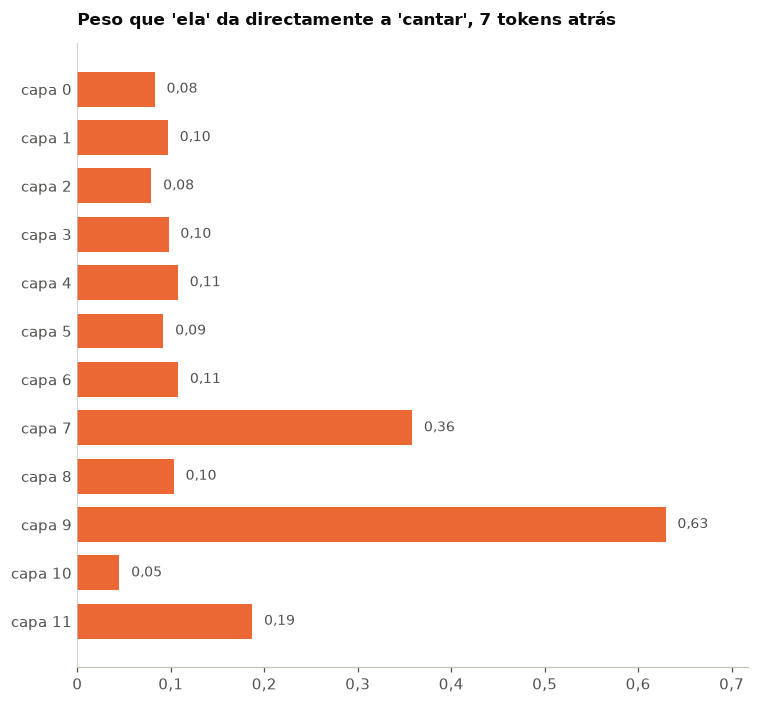

In [23]:
with torch.no_grad():
    salida_con_atencion = modelo(ids_del_verso, output_attentions=True)

posicion_de_ela = 11
nombres_de_capas = []
pesos_directos = []
cabezas_que_mas_dan = []
for numero_de_capa in range(12):
    capa = salida_con_atencion.attentions[numero_de_capa]
    # Todas las cabezas; fila de 'ela', columna de 'cantar'.
    cabezas_de_la_capa = capa[0].numpy()
    pesos_de_ela = cabezas_de_la_capa[:, posicion_de_ela, posicion_de_cantar]
    nombres_de_capas.append(f"capa {numero_de_capa}")
    pesos_directos.append(pesos_de_ela.max())
    cabezas_que_mas_dan.append(int(pesos_de_ela.argmax()))

print(f"Cabeza que mas da, por capa: {cabezas_que_mas_dan}")
utils.dibujar_barras(
    nombres=nombres_de_capas,
    valores=pesos_directos,
    titulo="Peso que 'ela' da directamente a 'cantar', 7 tokens atr\u00e1s",
    color=utils.NARANJA,
)

> **Para mirar.** En la capa 9, la cabeza 9 lleva el 63 % del peso de «ela» directamente a «cantar», sin pasar por los tokens del medio. Eso muestra que el modelo **usa** la conexión directa. No muestra que «entienda» la relación entre el canto y la vigüela: es una cabeza, en un verso.

## Qué te llevás

- Un modelo no recibe palabras: recibe la fila de su token en una tabla de embeddings **más** el vector de su posición. Esos números se aprendieron, y vectores parecidos no siempre son palabras parecidas.
- Una neurona multiplica lo que entra por sus pesos, suma y agrega un sesgo; su salida se arma con cientos de aportes chicos, y un nombre puesto por un solo ejemplo («la neurona de cantar») no resiste una prueba.
- Leer en cadena obliga a pasar por todos los pasos; la atención permite conexiones directas, y GPT-2 las usa: «ela» toma 63 % de «cantar» en una cabeza.

**Sigue:** en el cuaderno 02, cómo calcula la atención esos pesos, cuenta por cuenta.